# TDCS: fixed candidate experiment log

## tl;dr

The best of this bounded six-candidate comparison was **neural_hgb_equal**:
**0.3800 pooled native-row TDCS OOF mAP**, versus
**0.3512** for the previous neural blend
and **0.3642** for the sensor HGB model.
Change versus sensor HGB: **+0.0158**.

Selected class AP: StartHesitation **0.1848**,
Turn **0.7808**, Walking **0.1744**.
The saved native-row predictions passed an independent rank-based AP check.

These are development validation results, not leaderboard scores. The same
folds have been reused across experiments, so choosing the best candidate
can make the reported improvement optimistic. DeFOG's reported **0.817**
remains untouched. No Kaggle submission or scoring request is made.

## Context & Methods

Goal: improve TDCS mAP separately from DeFOG. All candidates use the same
815 recordings, 61 subjects, and frozen five subject-disjoint folds. A subject's
recordings never appear in both the training and validation set of a fold.
Average precision is pooled over **every native row** separately for the three
targets, then averaged. The mean of fold mAPs is not this pooled metric.

A new independent CatBoost classifier is trained for each target and fold,
using the existing 101 label-free multiscale accelerometer features. Settings:
400 iterations, depth 6, learning rate 0.05, L2 leaf regularization 10,
128 bins, and square-root positive weighting capped at 8. There is no eval_set,
random-row early stopping, or selection of tree count on outer-fold labels.
Settings and blend weights were written before the new run was evaluated.
API reference: [CatBoostClassifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier).

The six compared candidates are the old neural blend, sensor HGB, sensor
CatBoost, equal neural/HGB blend, equal HGB/CatBoost blend, and a three-way
blend with 50% neural, 25% HGB, and 25% CatBoost. All weights are the same
for all three targets; there is no weight sweep or learned stacking.

### Key Assumptions

- The public example's subject `4dc2f8` remains excluded for comparability.
- Sensor features use accelerometer values and timing, not subject identity,
  labels, event intervals, or clinical inputs.
- Centered windows and whole-record normalization are offline features.
  This is not a causal real-time detector.
- Repeated validation reuse and selecting among six candidates remain
  development-time model selection. Fresh subjects or fully nested retraining
  are needed for an independent generalization estimate.
- The neural models' existing folds are checked against the sensor manifest.
  Fixed blends do not fit a second-stage model on OOF labels.

## Data

This notebook is an experiment log: by default it reads completed artifacts,
verifies the saved checks, and rebuilds comparison figures. Training was run
separately with the reproducible companion script. It requires this project
and its cached TDCS inputs, not a Kaggle scoring endpoint.

Inputs: `data/raw/train/tdcsfog`, `data/metadata/tdcsfog_metadata.csv`,
the independently verified sensor run under `results/tdcs_multiscale_signal`,
and downloaded neural OOF predictions under
`kaggle-output/fog-evidence-weighted/competition/neural/tdcsfog`.

To rerun all six candidates from the project root:

```powershell
.\.venv\Scripts\python.exe -u scripts/tdcs_candidate_sweep.py
```

Completed target/fold models are reused only for the matching source,
configuration, input-cache fingerprint, and CatBoost version. The selected
native-row OOF predictions are saved separately; earlier candidates are not
overwritten.

### Load this project's completed experiment

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

possible_roots = [Path.cwd(), *Path.cwd().parents, Path('D:/Dissertation')]
PROJECT_ROOT = next(path for path in possible_roots
                    if (path / 'scripts' / 'tdcs_candidate_sweep.py').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
import tdcs_candidate_sweep as experiment

decision = json.loads((PROJECT_ROOT / 'results' / 'tdcs_candidate_sweep' / 'latest_run.json').read_text())
run_dir = Path(decision['run_dir'])
metrics = pd.read_csv(run_dir / 'candidate_metrics.csv')
fold_metrics = pd.read_csv(run_dir / 'candidate_fold_metrics.csv')
configuration = json.loads((run_dir / 'predeclared_configuration.json').read_text())
audit = json.loads((run_dir / 'audit.json').read_text())
validation = json.loads((Path(decision['selected_candidate_dir']) / 'validation.json').read_text())
print('Experiment artifacts:', run_dir)

Experiment artifacts: D:\Dissertation\results\tdcs_candidate_sweep\be33b80da0759c91c255


### Check validation scope and numerical reconciliation

In [2]:
assert validation['status'] == 'passed'
assert validation['native_rows'] == audit['native_rows'] == 6959762
assert validation['recordings'] == audit['recordings'] == 815
assert validation['subjects'] == audit['subjects'] == 61
assert validation['subject_disjoint'] and validation['prediction_ids_exact_match']
selected = metrics.loc[metrics.method.eq(decision['selected_method'])].iloc[0]
for target in [*experiment.TARGETS, 'mAP']:
    assert abs(selected[target] - validation['independent_rank_based_AP'][target]) < 1e-10
assert audit['competition_submission_created'] is False
assert audit['retained_defog_reported_oof_map'] == 0.817
display(pd.DataFrame([{'check': key, 'value': audit[key]} for key in
                     ['recordings', 'subjects', 'native_rows', 'sampled_training_rows',
                      'feature_count', 'validation', 'evaluation_grain']]))
print('Independent AP check: passed. Reused development folds: selection remains exploratory.')

Independent AP check: passed. Reused development folds: selection remains exploratory.


,check,value
0,recordings,815
1,subjects,61
2,native_rows,6959762
3,sampled_training_rows,218670
4,feature_count,101
5,validation,same five frozen subject-disjoint folds
6,evaluation_grain,"every native row, pooled AP per target, arithm..."


### Inspect the fixed blends and CatBoost settings

In [3]:
display(pd.DataFrame(configuration['fixed_blends']).fillna(0).T)
display(pd.DataFrame([configuration['catboost_parameters']]))

,previous_tdcs_blend,multiscale_sensor_hgb,multiscale_catboost
neural_hgb_equal,0.5,0.50,0.00
hgb_catboost_equal,0.0,0.50,0.50
neural_sensor_three_way,0.5,0.25,0.25


,iterations,learning_rate,depth,l2_leaf_reg,loss_function,border_count,bootstrap_type,bagging_temperature,random_strength,rsm,thread_count,task_type,use_best_model,allow_writing_files,verbose
0,400,0.05,6,10.0,Logloss,128,Bayesian,0.8,1.0,0.85,4,CPU,False,False,False


## Results

### Compare all candidates on the same native rows

In [4]:
display(metrics.sort_values('mAP', ascending=False).style.format(
    {name: '{:.4f}' for name in [*experiment.TARGETS, 'mAP']}))
figures = experiment.make_figures(metrics, run_dir)

,method,StartHesitation,Turn,Walking,mAP
3,neural_hgb_equal,0.1848,0.7808,0.1744,0.3800
5,neural_sensor_three_way,0.1871,0.7761,0.1697,0.3777
1,multiscale_sensor_hgb,0.1530,0.7884,0.1513,0.3642
4,hgb_catboost_equal,0.1453,0.7866,0.1218,0.3513
0,previous_tdcs_blend,0.1868,0.7161,0.1506,0.3512
2,multiscale_catboost,0.1380,0.7690,0.0872,0.3314


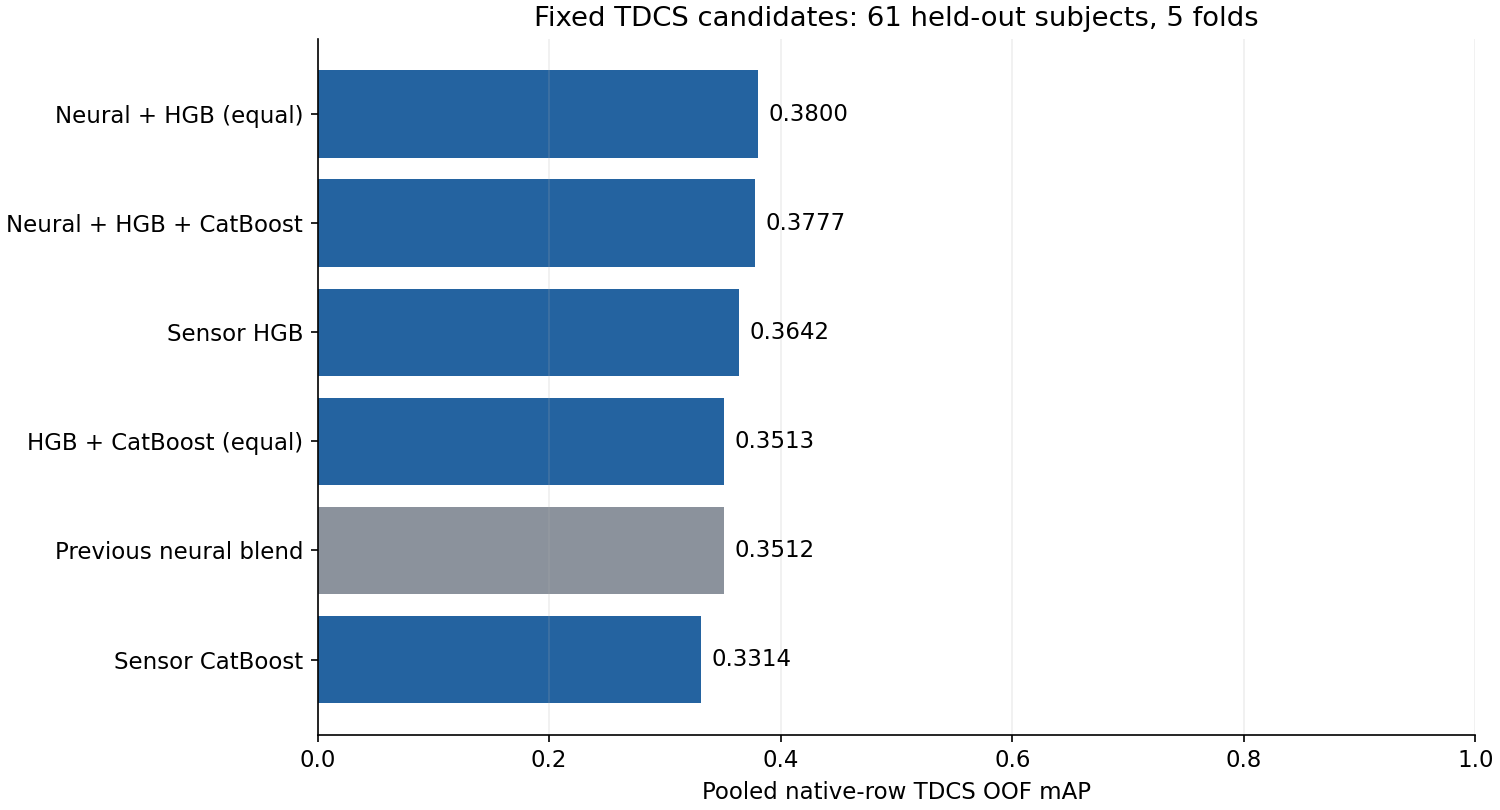

In [5]:
display(Image(filename=str(figures[0])))

### Check whether gains cover all three target classes

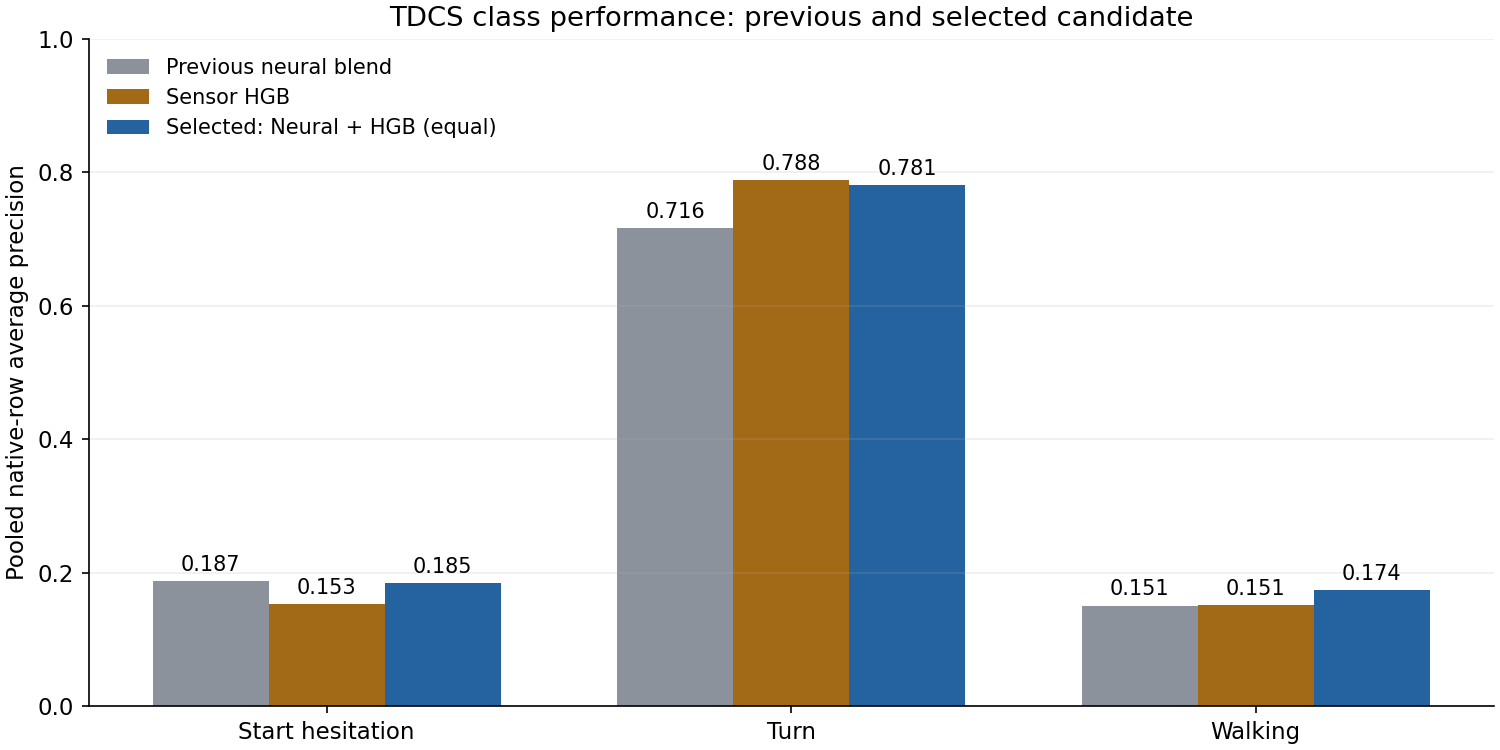

In [6]:
display(Image(filename=str(figures[1])))

### Examine held-out subject-fold variation

These five scores describe observed variation, not a confidence interval.
Target prevalence and difficulty vary by subject. Use the pooled native-row
results above for the primary comparison.

In [7]:
selected_folds = fold_metrics.loc[fold_metrics.method.eq(decision['selected_method'])]
display(selected_folds.style.format({name: '{:.4f}' for name in [*experiment.TARGETS, 'mAP']}))

,method,fold,StartHesitation,Turn,Walking,mAP
15,neural_hgb_equal,0,0.3697,0.8326,0.1959,0.4660
16,neural_hgb_equal,1,0.1117,0.7811,0.2149,0.3692
17,neural_hgb_equal,2,0.1630,0.6973,0.0540,0.3048
18,neural_hgb_equal,3,0.0496,0.8462,0.0725,0.3227
19,neural_hgb_equal,4,0.0546,0.8090,0.0690,0.3109


## Takeaways

Retain the best candidate as a separate TDCS experiment, with its measured
per-class tradeoffs and validation caveat. Do not overwrite the previous
models or DeFOG. The next independent assessment should use new held-out
subjects or fully nested training, not tune against hidden leaderboard data.

In [8]:
print(f"Selected TDCS candidate: {decision['selected_method']}")
print(f"Native-row OOF mAP: {decision['candidate_tdcs_oof_map']:.4f}")
print(f"Change vs previous neural blend: {decision['delta_vs_neural']:+.4f}")
print(f"Change vs previous sensor HGB: {decision['delta_vs_sensor']:+.4f}")
print('DeFOG reported 0.817 retained; no leaderboard scoring or submission.')
print('Selection among reused development OOF results is exploratory.')

Selected TDCS candidate: neural_hgb_equal
Native-row OOF mAP: 0.3800
Change vs previous neural blend: +0.0288
Change vs previous sensor HGB: +0.0158
DeFOG reported 0.817 retained; no leaderboard scoring or submission.
Selection among reused development OOF results is exploratory.
